In [1]:
import torch
import torch.nn
import torchvision.models as models
import torchvision.transforms as transforms
import torch.nn.functional as F
import matplotlib.pyplot as plt
import numpy as np
from PIL import Image
import PIL.Image

In [2]:
alexnet = models.alexnet(weights=models.AlexNet_Weights.IMAGENET1K_V1)
alexnet.eval()

def predict_image(image, alexnet):
    data_transforms = transforms.Compose([
        transforms.Resize((224,224)),       # Set image size to 224x224
        transforms.ToTensor(),              # Set to Tensor format
        transforms.Normalize( # Normalization with mean and std values
            mean=[0.485, 0.456, 0.406], 
            std=[0.229, 0.224, 0.225]
        )])
    # Open and transform the image
    transformed_img = data_transforms(image)
    batch_img = torch.unsqueeze(transformed_img, 0)
    
    output = alexnet(batch_img)

    sorted, indices = torch.sort(output, descending=True)
    percentage = F.softmax(output, dim=1)[0] * 100.0 
    
    return indices, percentage

In [3]:
img_original = Image.open('./Images/tiger.jpg').convert("RGB")
originalSlikaBaseball = Image.open('./Images/bejzbol.JPEG').convert("RGB")

In [4]:
def img_to_1d(img):
    if isinstance(img, Image.Image):
        img = np.array(img)
    shape = img.shape
    img = img.reshape(-1)
    img_flat = img.astype(np.float32) / 255.0
    return shape, img_flat

def img_from_1d(img, shape):
    restored_image = (img * 255).astype(np.uint8)
    restored_image = restored_image.reshape(shape)
    return restored_image

In [5]:
from niapy.algorithms.basic import ParticleSwarmAlgorithm
from niapy.problems import Problem
from niapy.task import Task, OptimizationType

class TestBenchmark(Problem):
    def __init__(self, search):
        dimension = len(search)
        lower = 0
        upper = 1
        super().__init__(dimension, lower, upper)

        self.search = search

    def _evaluate(self, solution):
        difference = 0
        for i in range(len(solution)):
            difference = difference + abs(self.search[i] - solution[i])

        return difference

shape, img_search = img_to_1d(img_original)

algorithm = ParticleSwarmAlgorithm(population_size=50)  # Changed NP to population_size

n = len(img_search)
test = np.empty(n, dtype=object)
search = np.empty(3, dtype=object)

for i in range(0, len(img_search), 3):
    search[0] = img_search[i]
    search[1] = img_search[i + 1]
    search[2] = img_search[i + 2]

    benchmark = TestBenchmark(search=search)

    # Replace StoppingTask with Task
    task = Task(
        problem=benchmark,
        max_evals=20,                  # Was nFES=20
        optimization_type=OptimizationType.MINIMIZATION  # Was optType=OptimizationType.MINIMIZATION
    )

    solution, fitness = algorithm.run(task=task)
    test[i] = solution[0]
    test[i+1] = solution[1]
    test[i+2] = solution[2]

print("search: ", search)
print("solution: ", solution)
print("fitness: ", fitness)

search:  [np.float32(0.30980393) np.float32(0.4627451) np.float32(0.2901961)]
solution:  [0.34863354 0.42346127 0.20088814]
fitness:  0.1674213857840997


In [6]:
shape_tiger, img_search = img_to_1d(img_original)

algorithm = ParticleSwarmAlgorithm(population_size=20)  # Changed NP=20 to population_size=20

n = len(img_search)
rangeFor = (int(n / 9))

solution_tiger = np.empty(n, dtype=object)
search = np.empty(9, dtype=object)

for i in range(rangeFor):
    i *= 9
    for j in range (9):
        search[j] = img_search[i + j]

    benchmark = TestBenchmark(search=search)
    task = Task(                          # Changed StoppingTask to Task
        problem=benchmark,                   # Changed benchmark=benchm to problem=benchm
        max_evals=70,                     # Changed nFES=70 to max_evals=70
        optimization_type=OptimizationType.MINIMIZATION  # Changed optType to optimization_type
    )

    solution, fitness = algorithm.run(task=task)

    for j in range (9):
        solution_tiger[i + j] = solution[j]

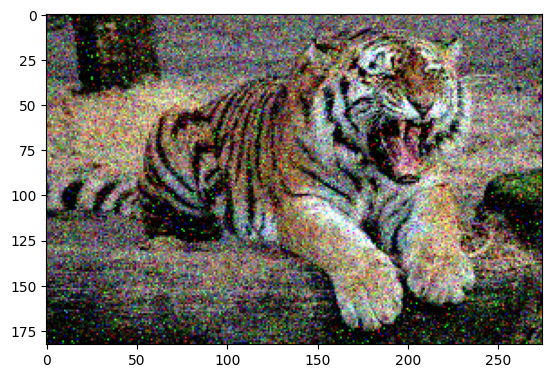

Predicted class: lion, king of beasts, Panthera leo 
The algorithm claims this with a certainty of 66.64%


In [7]:
solution_tiger_flat = solution_tiger.astype(float)
solution_tiger_img = img_from_1d(solution_tiger_flat, shape_tiger)

PIL_image = PIL.Image.fromarray(np.uint8(solution_tiger_img)).convert('RGB')

plt.imshow(np.array(PIL_image))
plt.show()

indices, percentage = predict_image(PIL_image, alexnet)

with open('./ILVRSC ImageNet Labels/class_names_ImageNet.txt') as labels:
    classes = [i.strip() for i in labels.readlines()]

    results = [(classes[i], percentage[i].item()) for i in indices[0][:5]]
    print('Predicted class: ' + str(results[0][0]) + ' \nThe algorithm claims this with a certainty of %.2f' %(results[0][1])+'%')


# Changing only a part of the image?

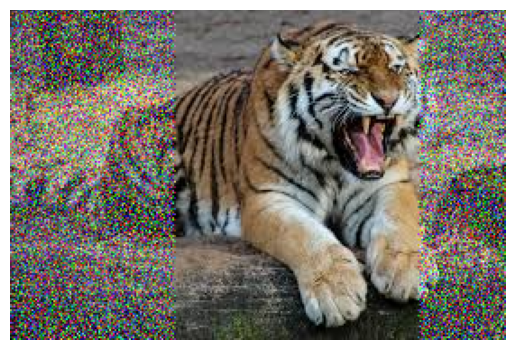

Predicted class: lion, king of beasts, Panthera leo 
The algorithm claims this with a certainty of 92.44%


In [8]:
# Flatten the image
shape, img_search = img_to_1d(img_original)

# Initialize the PSO algorithm
algorithm = ParticleSwarmAlgorithm(population_size=10)

n = len(img_search)
step = 9  # process 9 channels at a time

# Prepare array to hold the result
search_tiger = np.empty(n, dtype=object)

for i in range(0, n, step):
    # Dynamic slice for the current group
    search = img_search[i:i + step].copy()  # ensures proper size at end

    # Only run optimization for left/right margins
    col_pos = (i // 3) % 275  # convert flattened index to pixel column
    if (0 < col_pos < 90) or (225 < col_pos < 275):
        benchmark = TestBenchmark(search=search)
        task = Task(
            problem=benchmark,
            max_evals=15,
            optimization_type=OptimizationType.MINIMIZATION
        )

        solution, fitness = algorithm.run(task=task)
        search_tiger[i:i + len(solution)] = solution
    else:
        # Leave center columns unchanged
        search_tiger[i:i + len(search)] = search

# Restore the image
solution_tiger_two = img_from_1d(search_tiger, shape)

# Display image correctly
plt.imshow(solution_tiger_two)
plt.axis('off')
plt.show()

# Prepare for CNN classification
PIL_image = PIL.Image.fromarray(np.uint8(solution_tiger_two)).convert('RGB')

indices, percentage = predict_image(PIL_image, alexnet)

with open('./ILVRSC ImageNet Labels/class_names_ImageNet.txt') as labels:
    classes = [i.strip() for i in labels.readlines()]

results = [(classes[i], percentage[i].item()) for i in indices[0][:5]]
print('Predicted class: ' + str(results[0][0]) +
      ' \nThe algorithm claims this with a certainty of %.2f' % (results[0][1]) + '%')

Average difference in pixel colour:  11.843891502669376


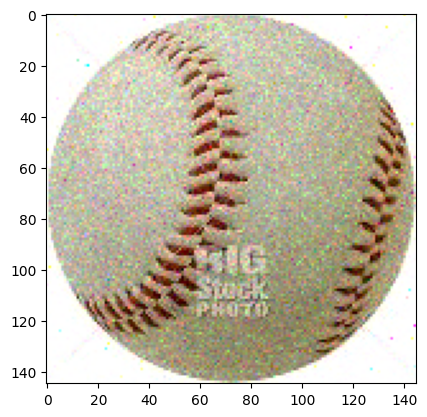

Predicted class: barrow, garden cart, lawn cart, wheelbarrow 
The algorithm claims this with a certainty of 100.00%


In [9]:
img_original = Image.open('./Images/bejzbol.JPEG')

shape, img_search = img_to_1d(img_original)

algorithm = ParticleSwarmAlgorithm(population_size=10)

n = len(img_search)
rangeFor = (int(n / 3))

resitevTigerTri = np.empty(n, dtype=object)
search = np.empty(3, dtype=object)
fitnes = 0

for i in range(rangeFor):
    i *= 3
    for j in range (3):
        search[j] = img_search[i + j]

    benchmark = TestBenchmark(search=search)
    task = Task(
        problem=benchmark,          # Use Task instead of StoppingTask
        max_evals=40,               # nFES -> max_evals
        optimization_type=OptimizationType.MINIMIZATION
    )


    solution, fitness = algorithm.run(task=task)
    fitnes += fitness
    for j in range (3):
        resitevTigerTri[i+j] = solution[j]

fitnes = (fitnes/n)*255
print("Average difference in pixel colour: ", fitnes)

TigerThree = img_from_1d(resitevTigerTri, shape)
plt.imshow(TigerThree)
plt.show()

PIL_image = PIL.Image.fromarray(np.uint8(TigerThree)).convert('RGB')

indices, percentage = predict_image(PIL_image, alexnet)
with open('./ILVRSC ImageNet Labels/class_names_ImageNet.txt') as labels:
    classes = [i.strip() for i in labels.readlines()]

    results = [(classes[i], percentage[i].item()) for i in indices[0][:5]]
    print('Predicted class: ' + str(results[0][0]) + ' \nThe algorithm claims this with a certainty of %.2f' %(results[0][1])+'%')